
STUDENT PERFORMANCE DATASET
    Study_Hours  Attendance  Previous_Marks  Assignment_Marks  Final_Marks  \
0             2          50              30                35           32   
1             5          85              75                80           78   
2             1          40              25                30           28   
3             6          90              85                90           88   
4             3          65              45                50           48   
5             7          95              90                95           92   
6             2          45              35                40           35   
7             8          98              95                98           96   
8             4          75              60                65           62   
9             5          80              70                75           73   
10            1          35              20                25           22   
11            6          88        

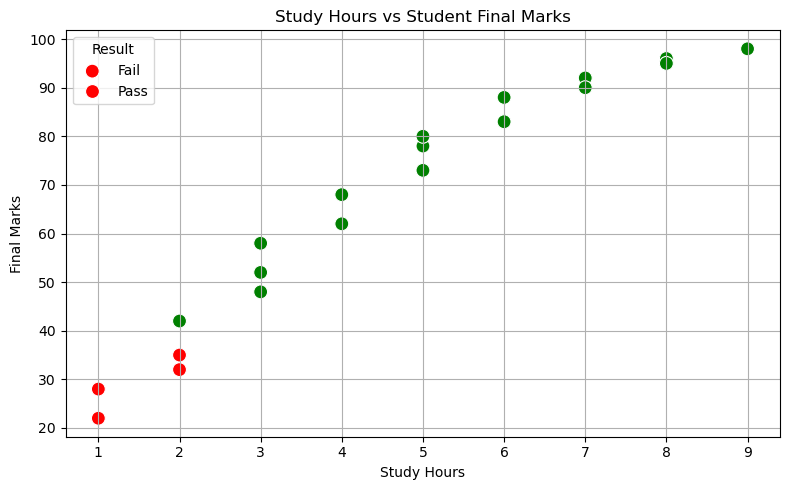

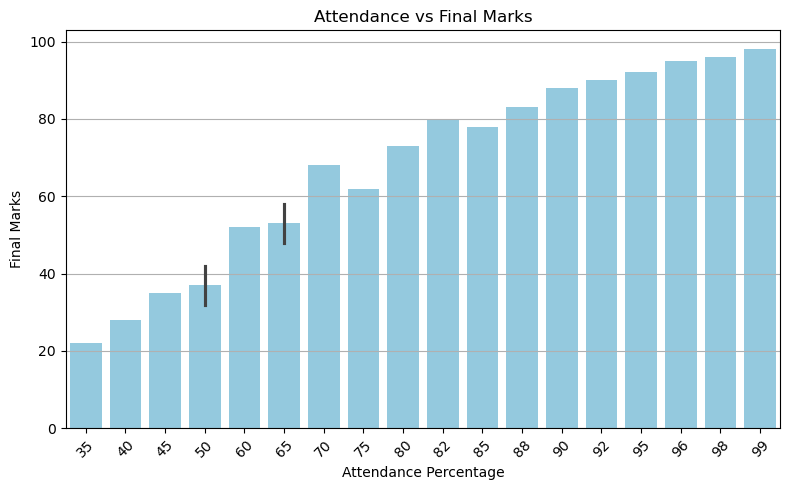

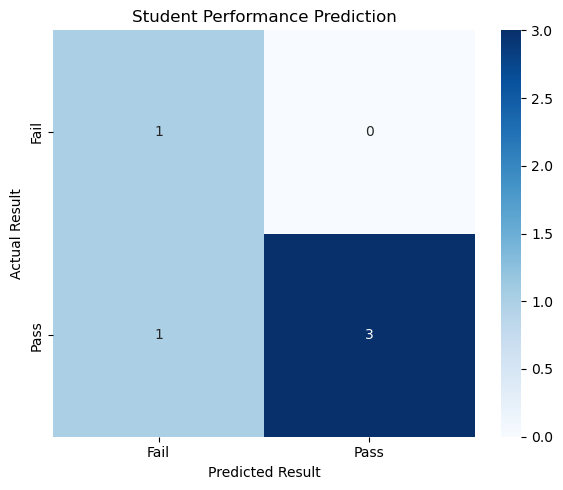


NEW STUDENT PERFORMANCE PREDICTION
----------------------------------


Enter Study Hours:  2
Enter Attendance Percentage:  50
Enter Previous Exam Marks:  78
Enter Assignment Marks:  20



Predicted Result: PASS

Project Execution Completed!


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ---------------------------------------
# 1. CREATE STUDENT DATASET
# ---------------------------------------

data = {
    'Study_Hours': [2, 5, 1, 6, 3, 7, 2, 8, 4, 5,
                    1, 6, 3, 9, 2, 7, 4, 8, 5, 3],

    'Attendance': [50, 85, 40, 90, 65, 95, 45, 98, 75, 80,
                   35, 88, 60, 99, 50, 92, 70, 96, 82, 65],

    'Previous_Marks': [30, 75, 25, 85, 45, 90, 35, 95, 60, 70,
                       20, 80, 50, 98, 40, 88, 65, 94, 78, 55],

    'Assignment_Marks': [35, 80, 30, 90, 50, 95, 40, 98, 65, 75,
                         25, 85, 55, 99, 45, 92, 70, 96, 82, 60],

    'Final_Marks': [32, 78, 28, 88, 48, 92, 35, 96, 62, 73,
                    22, 83, 52, 98, 42, 90, 68, 95, 80, 58]
}

df = pd.DataFrame(data)

# ---------------------------------------
# 2. DATA PREPROCESSING
# ---------------------------------------

df['Result'] = np.where(df['Final_Marks'] >= 40, 1, 0)

print("\nSTUDENT PERFORMANCE DATASET")
print(df)

print("\nDataset Information:")
print(df.describe())

# ---------------------------------------
# 3. MACHINE LEARNING MODEL
# ---------------------------------------

X = df[['Study_Hours', 'Attendance',
        'Previous_Marks', 'Assignment_Marks']]

y = df['Result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42,
    stratify=y
)

model = LogisticRegression()

model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nMACHINE LEARNING RESULTS")
print("------------------------")
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            zero_division=0))

# ---------------------------------------
# 4. GRAPH 1: STUDY HOURS VS FINAL MARKS
# ---------------------------------------

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Study_Hours',
    y='Final_Marks',
    hue='Result',
    data=df,
    palette={0: 'red', 1: 'green'},
    s=100
)

plt.title("Study Hours vs Student Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.legend(title="Result", labels=["Fail", "Pass"])
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------------------------------
# 5. GRAPH 2: ATTENDANCE VS FINAL MARKS
# ---------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    x='Attendance',
    y='Final_Marks',
    data=df,
    color='skyblue'
)

plt.title("Attendance vs Final Marks")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Marks")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# ---------------------------------------
# 6. GRAPH 3: CONFUSION MATRIX
# ---------------------------------------

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.title("Student Performance Prediction")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.tight_layout()
plt.show()

# ---------------------------------------
# 7. PREDICT NEW STUDENT PERFORMANCE
# ---------------------------------------

print("\nNEW STUDENT PERFORMANCE PREDICTION")
print("----------------------------------")

study = float(input("Enter Study Hours: "))
attendance = float(input("Enter Attendance Percentage: "))
previous = float(input("Enter Previous Exam Marks: "))
assignment = float(input("Enter Assignment Marks: "))

new_student = pd.DataFrame(
    [[study, attendance, previous, assignment]],
    columns=['Study_Hours', 'Attendance',
             'Previous_Marks', 'Assignment_Marks']
)

prediction = model.predict(new_student)

if prediction[0] == 1:
    print("\nPredicted Result: PASS")
else:
    print("\nPredicted Result: FAIL")

print("\nProject Execution Completed!")
